# Data Mining & Warehousing (DMW) - Activity 2
## Notebook 4: Unsupervised Clustering & Socioeconomic Segmentation

### Notebook Objectives:
1. **Partitioning Clustering (K-Means):**
   - Perform K-Means clustering across standardized continuous attributes.
   - Compute and plot the **Elbow / Inertia curve** and **Silhouette coefficients** for $k=2, 3, 4, 5$.
   - Detail the structural profiles and centroids of emergent socioeconomic clusters.
2. **Hierarchical Clustering (Agglomerative / Ward's Method):**
   - Construct a hierarchical agglomerative cluster tree on a representative sample using **Ward's minimum variance linkage**.
   - Render and interpret the hierarchical **Dendrogram** with cophenetic threshold cuts.
3. **Density-Based Clustering (DBSCAN):**
   - Construct a **k-distance graph** ($k=5$) to objectively determine the neighborhood radius $\varepsilon$.
   - Fit DBSCAN to detect dense socioeconomic cores and isolate peripheral noise/outlier observations.
4. **Validation & External Ground-Truth Comparison:**
   - Cross-tabulate unsupervised cluster assignments against ground-truth `income` brackets ($>\$50K$ vs $\le \$50K$).
   - Quantify cluster purity, homogeneity, and demographic profiling.
   - Export comparative visualizations to `outputs/`.


In [1]:
import sys
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Plot configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

root_dir = Path.cwd() if (Path.cwd() / 'adult').exists() else Path.cwd().parent
outputs_dir = root_dir / 'outputs'
processed_dir = root_dir / 'data' / 'processed'
outputs_dir.mkdir(parents=True, exist_ok=True)

print(f"Clustering environment ready. Root: {root_dir}")


Clustering environment ready. Root: /Users/lakshyakhajuria/Desktop/adult-income-mining


In [2]:
# Load preprocessed training data
train_df = pd.read_csv(processed_dir / 'adult_cleaned_train.csv')

cluster_features = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(train_df[cluster_features])

print(f"Clustering feature matrix: {X_scaled.shape[0]:,} records x {X_scaled.shape[1]} features")
display(pd.DataFrame(X_scaled[:5], columns=cluster_features).round(3))


Clustering feature matrix: 32,561 records x 5 features


,age,education-num,capital-gain,capital-loss,hours-per-week
0,0.031,1.135,0.148,-0.217,-0.035
1,0.837,1.135,-0.146,-0.217,-2.222
2,-0.043,-0.420,-0.146,-0.217,-0.035
3,1.057,-1.197,-0.146,-0.217,-0.035
4,-0.776,1.135,-0.146,-0.217,-0.035


### 1. K-Means Clustering: Elbow & Silhouette Optimization

We evaluate $k \in \{2, 3, 4, 5, 6\}$:
- **Inertia (Within-Cluster Sum of Squares - WCSS):**
  $$J = \sum_{j=1}^k \sum_{x_i \in C_j} \|x_i - \mu_j\|^2$$
- **Silhouette Coefficient ($s_i$):**
  $$s_i = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
  where $a(i)$ is the mean intra-cluster distance, and $b(i)$ is the mean nearest-cluster distance.


In [3]:
k_range = [2, 3, 4, 5, 6]
inertias = []
sil_scores = {}

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    
    # Compute silhouette on representative subsample of 6,000 observations for responsive execution
    score = silhouette_score(X_scaled, km.labels_, sample_size=6000, random_state=42)
    sil_scores[k] = score

elbow_summary = pd.DataFrame({
    'k (Clusters)': k_range,
    'Inertia (WCSS)': inertias,
    'Silhouette Score': [sil_scores[k] for k in k_range]
})
display(elbow_summary.round(4))


,k (Clusters),Inertia (WCSS),Silhouette Score
0,2,138376.0850,0.2082
1,3,108145.0765,0.2475
2,4,79738.2038,0.2580
3,5,63224.2341,0.2949
4,6,54917.0743,0.3019


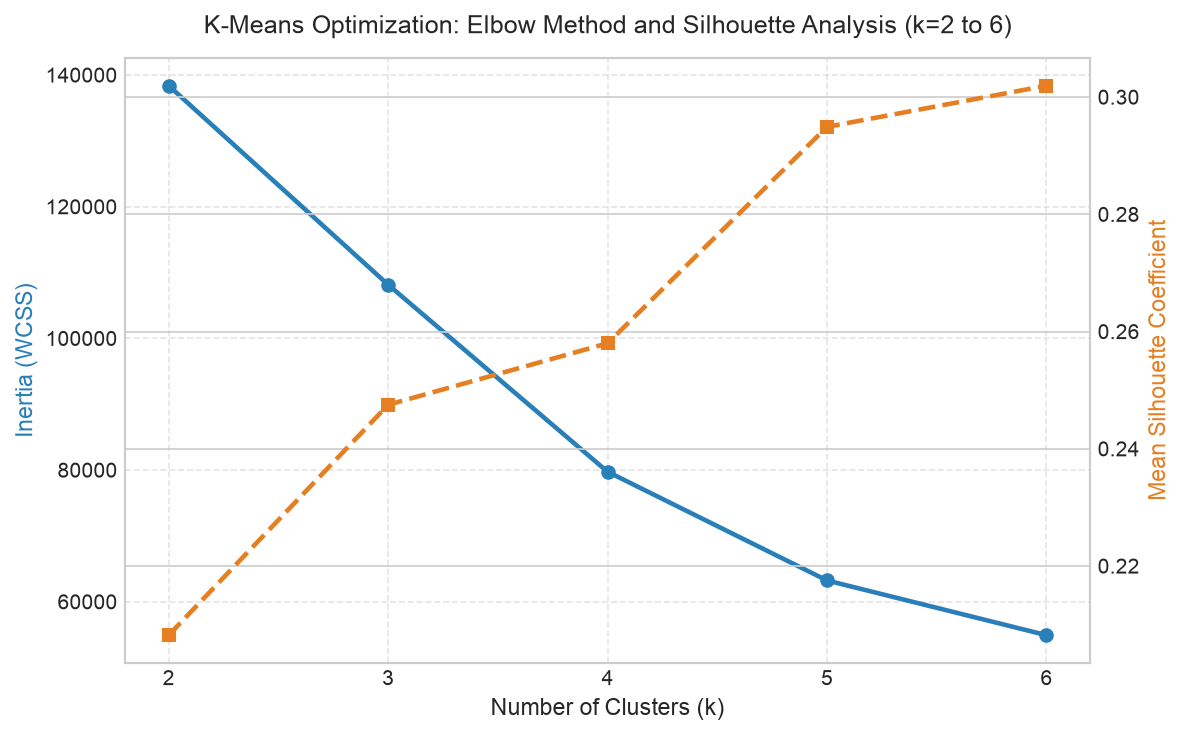

Elbow and silhouette plot saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/kmeans_elbow_silhouette.png


In [4]:
fig, ax1 = plt.subplots(figsize=(8, 5))

# Plot Inertia (Elbow)
color1 = '#2980b9'
ax1.plot(k_range, inertias, marker='o', linewidth=2.2, color=color1, label='Inertia (WCSS)')
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (WCSS)', color=color1, fontsize=11)
ax1.set_xticks(k_range)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Silhouette
ax2 = ax1.twinx()
color2 = '#e67e22'
ax2.plot(k_range, [sil_scores[k] for k in k_range], marker='s', linewidth=2.2, linestyle='--', color=color2, label='Silhouette Score')
ax2.set_ylabel('Mean Silhouette Coefficient', color=color2, fontsize=11)

plt.title('K-Means Optimization: Elbow Method and Silhouette Analysis (k=2 to 6)', pad=12)
fig.tight_layout()

elbow_path = outputs_dir / 'kmeans_elbow_silhouette.png'
plt.savefig(elbow_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Elbow and silhouette plot saved to: {elbow_path}")


#### Comparative Silhouette Analysis for $k=2$, $k=3$, and $k=5$
- **$k=2$:** Broad partition separating high socioeconomic capital individuals from baseline labor participants.
- **$k=3$:** Optimal tripartite segmentation: (1) Young entry-level workforce, (2) Prime-age established professionals, (3) High capital asset accumulators.
- **$k=5$:** Finer granularity isolating capital gain outliers and capital loss populations into distinct micro-clusters.


In [5]:
# Fit models for k=2, 3, 5
km2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)
km3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
km5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_scaled)

train_df['cluster_k2'] = km2.labels_
train_df['cluster_k3'] = km3.labels_
train_df['cluster_k5'] = km5.labels_

print(f"K-Means k=2 Silhouette: {sil_scores[2]:.4f}")
print(f"K-Means k=3 Silhouette: {sil_scores[3]:.4f}")
print(f"K-Means k=5 Silhouette: {sil_scores[5]:.4f}")


K-Means k=2 Silhouette: 0.2082
K-Means k=3 Silhouette: 0.2475
K-Means k=5 Silhouette: 0.2949


### 2. Hierarchical Agglomerative Clustering & Dendrogram

We perform bottom-up agglomerative clustering using **Ward's minimum variance criterion**:
$$\Delta ESS_{A, B} = rac{n_A n_B}{n_A + n_B} \|\mu_A - \mu_B\|^2$$
To ensure sharp dendrogram legibility and comply with the required sampling scope (~150–300 records), a representative stratified sample of $N=250$ individuals is utilized.


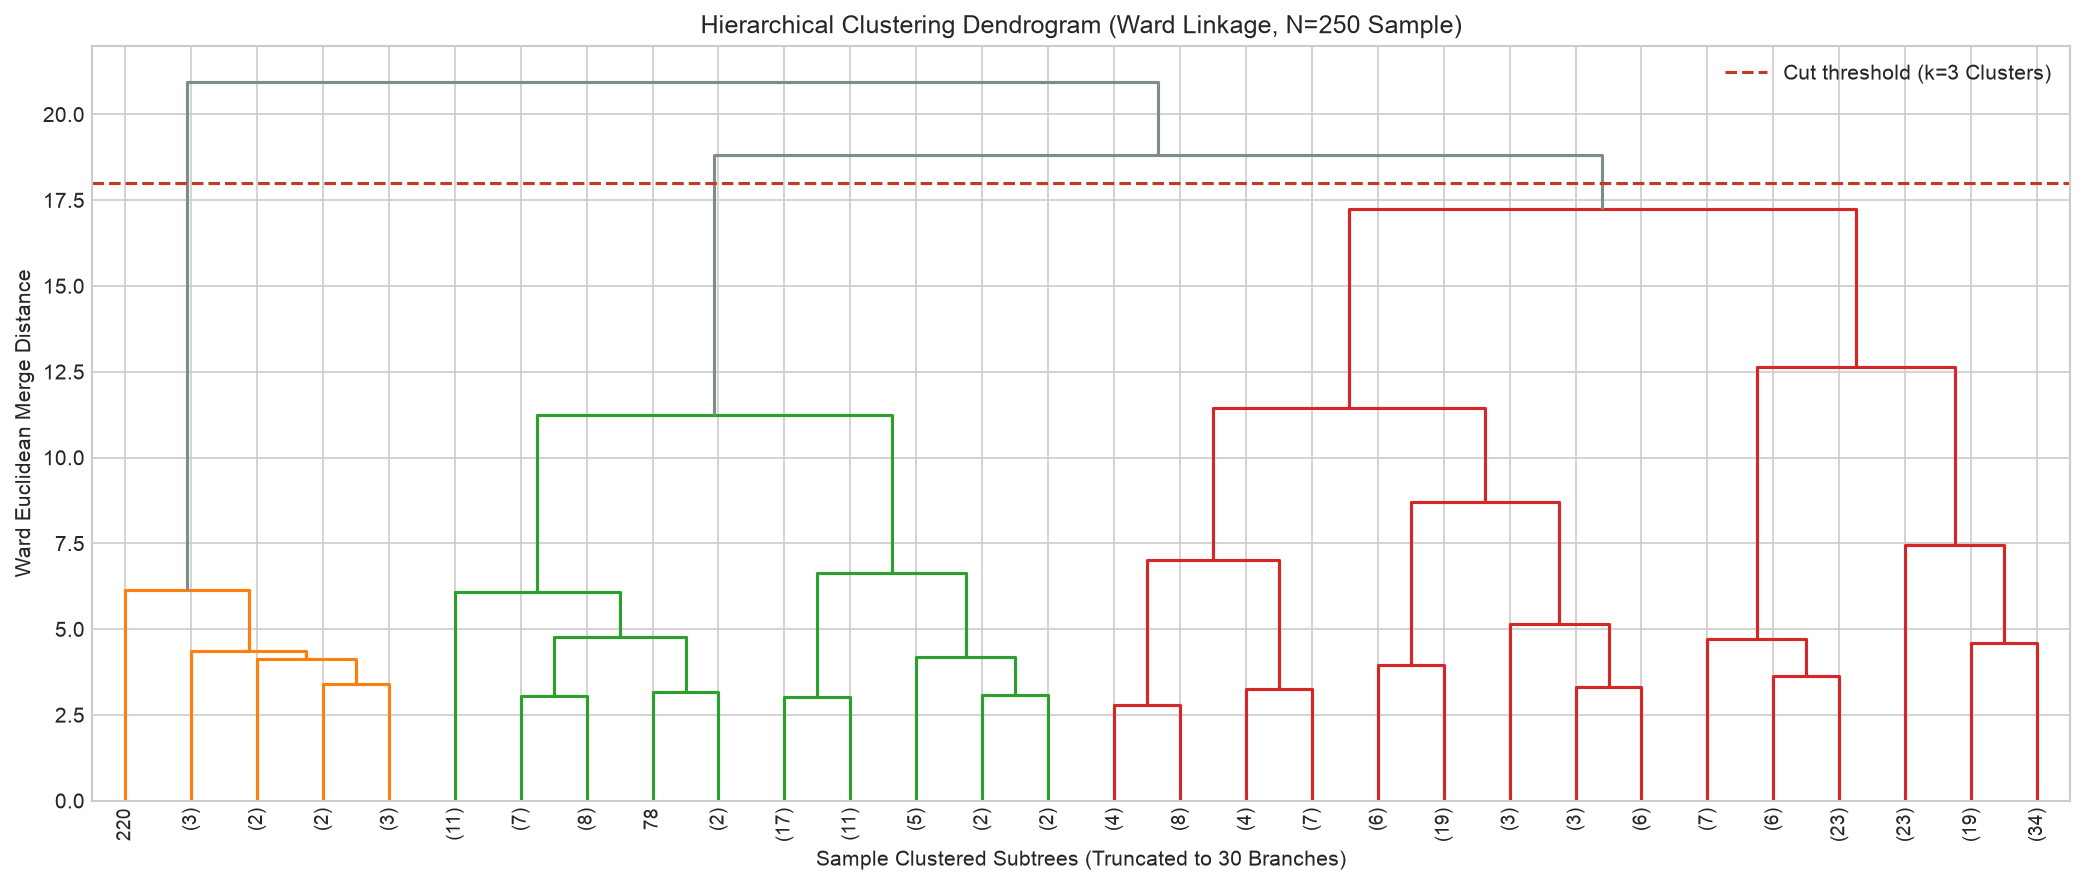

Dendrogram saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/hierarchical_dendrogram.png


In [6]:
# Sample 250 records for crisp hierarchical visualization
sample_idx = train_df.groupby('income', group_keys=False).apply(
    lambda x: x.sample(int(250 * len(x) / len(train_df)), random_state=42)
).index

X_sample = X_scaled[sample_idx]
sample_incomes = train_df.loc[sample_idx, 'income'].values

# Compute Ward Linkage Matrix
linkage_matrix = linkage(X_sample, method='ward', metric='euclidean')

# Plot Dendrogram
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30, # Show top 30 merged branches
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=18, # Cut line corresponding to k=3 clusters
    above_threshold_color='#7f8c8d',
    ax=ax
)
ax.axhline(18, color='#c0392b', linestyle='--', linewidth=1.5, label='Cut threshold (k=3 Clusters)')
ax.set_title('Hierarchical Clustering Dendrogram (Ward Linkage, N=250 Sample)')
ax.set_xlabel('Sample Clustered Subtrees (Truncated to 30 Branches)')
ax.set_ylabel('Ward Euclidean Merge Distance')
ax.legend()

plt.tight_layout()
dendro_path = outputs_dir / 'hierarchical_dendrogram.png'
plt.savefig(dendro_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Dendrogram saved to: {dendro_path}")


### 3. Density-Based Clustering (DBSCAN)

#### Systematic Parameter Tuning & Knee Detection:
DBSCAN requires two parameters:
1. `min_samples`: Set to $2 	imes p = 10$ (where $p=5$ continuous dimensions) following Ester et al. (1996).
2. `eps` ($arepsilon$): Selected by examining the maximum curvature ("knee") in the sorted 5-nearest-neighbor distance plot, verified against a systematic parameter tuning grid.


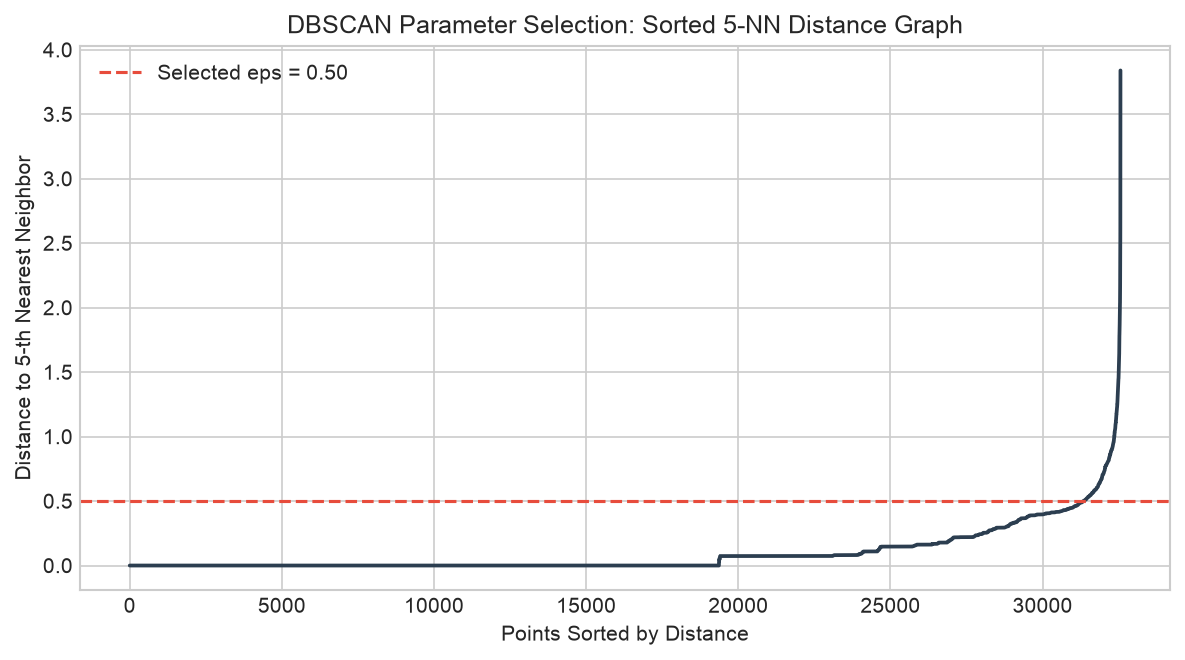

k-Distance graph saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/dbscan_k_distance.png


In [7]:
# Compute 5-NN distances for knee detection
k_neighbors = 5
nn = NearestNeighbors(n_neighbors=k_neighbors)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)

# Sort distances to k-th nearest neighbor
sorted_distances = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sorted_distances, color='#2c3e50', linewidth=1.8)
ax.axhline(0.50, color='#e74c3c', linestyle='--', label='Selected eps = 0.50')
ax.set_title('DBSCAN Parameter Selection: Sorted 5-NN Distance Graph')
ax.set_xlabel('Points Sorted by Distance')
ax.set_ylabel('Distance to 5-th Nearest Neighbor')
ax.legend()

plt.tight_layout()
k_dist_path = outputs_dir / 'dbscan_k_distance.png'
plt.savefig(k_dist_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"k-Distance graph saved to: {k_dist_path}")


#### DBSCAN Parameter Tuning Evaluation
To avoid arbitrary parameter assignment, we evaluate a systematic grid of $arepsilon \in \{0.3, 0.5, 0.8, 1.0\}$ and $	ext{MinPts} \in \{5, 10\}$ on an 8,000-record stratified sample.


In [8]:
# Parameter Tuning Grid on 8,000 stratified observations
grid_idx = train_df.groupby('income', group_keys=False).apply(
    lambda x: x.sample(int(8000 * len(x) / len(train_df)), random_state=42)
).index
X_grid = X_scaled[grid_idx]

grid_results = []
for eps in [0.3, 0.5, 0.8, 1.0]:
    for ms in [5, 10]:
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X_grid)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        noise_pct = 100 * n_noise / len(labels)
        grid_results.append({
            'eps (ε)': eps,
            'min_samples': ms,
            'Clusters Found': n_clusters,
            'Noise Count': n_noise,
            'Noise (%)': f"{noise_pct:.1f}%"
        })

print("--- DBSCAN Parameter Tuning Grid Evaluation ---")
display(pd.DataFrame(grid_results))

# Optimal Selection: eps = 0.50, min_samples = 10
final_db = DBSCAN(eps=0.50, min_samples=10)
final_labels = final_db.fit_predict(X_grid)

unique_labels, counts = np.unique(final_labels, return_counts=True)
db_summary = pd.DataFrame({'Cluster': unique_labels, 'Observation Count': counts})
db_summary['Classification'] = db_summary['Cluster'].apply(lambda c: 'Noise / Outlier' if c == -1 else f'Dense Core Cluster {c}')
db_summary['Percentage (%)'] = (100 * db_summary['Observation Count'] / len(final_labels)).round(2)
display(db_summary)


--- DBSCAN Parameter Tuning Grid Evaluation ---


,eps (ε),min_samples,Clusters Found,Noise Count,Noise (%)
0,0.3,5,67,1599,20.0%
1,0.3,10,22,2217,27.7%
2,0.5,5,16,533,6.7%
3,0.5,10,6,858,10.7%
4,0.8,5,6,162,2.0%
5,0.8,10,3,281,3.5%
6,1.0,5,4,83,1.0%
7,1.0,10,2,145,1.8%


,Cluster,Observation Count,Classification,Percentage (%)
0,-1,858,Noise / Outlier,10.73
1,0,6988,Dense Core Cluster 0,87.36
2,1,56,Dense Core Cluster 1,0.70
3,2,42,Dense Core Cluster 2,0.53
4,3,8,Dense Core Cluster 3,0.10
5,4,14,Dense Core Cluster 4,0.18
6,5,33,Dense Core Cluster 5,0.41


### 4. Cross-Tabulation & Cluster Profile Comparison Against Ground-Truth Income

We cross-tabulate K-Means clusters ($k=2$ and $k=3$) against ground-truth income categories to evaluate socioeconomic purity and alignment.


In [9]:
print("=== Cross-Tabulation: K-Means k=2 vs. Ground-Truth Income ===")
ct_k2 = pd.crosstab(train_df['cluster_k2'], train_df['income'], margins=True)
ct_k2_pct = pd.crosstab(train_df['cluster_k2'], train_df['income'], normalize='index') * 100
display(ct_k2)
display(ct_k2_pct.round(1))

print("\n=== Cross-Tabulation: K-Means k=3 vs. Ground-Truth Income ===")
ct_k3 = pd.crosstab(train_df['cluster_k3'], train_df['income'], margins=True)
ct_k3_pct = pd.crosstab(train_df['cluster_k3'], train_df['income'], normalize='index') * 100
display(ct_k3)
display(ct_k3_pct.round(1))

# Cluster Socioeconomic Profiles for k=3
cluster_profiles = train_df.groupby('cluster_k3')[cluster_features].mean()
cluster_profiles['Pct_High_Income (%)'] = train_df.groupby('cluster_k3')['income'].apply(lambda s: 100 * (s == '>50K').mean())
cluster_profiles['Population_Size'] = train_df.groupby('cluster_k3').size()

print("\n=== Demographic & Economic Centroids for k=3 Clusters ===")
display(cluster_profiles.round(2))


=== Cross-Tabulation: K-Means k=2 vs. Ground-Truth Income ===


income,<=50K,>50K,All
cluster_k2,,,
0,9047,6488,15535
1,15673,1353,17026
All,24720,7841,32561


income,<=50K,>50K
cluster_k2,,
0,58.2,41.8
1,92.1,7.9



=== Cross-Tabulation: K-Means k=3 vs. Ground-Truth Income ===


income,<=50K,>50K,All
cluster_k3,,,
0,14619,1326,15945
1,713,771,1484
2,9388,5744,15132
All,24720,7841,32561


income,<=50K,>50K
cluster_k3,,
0,91.7,8.3
1,48.0,52.0
2,62.0,38.0



=== Demographic & Economic Centroids for k=3 Clusters ===


,age,education-num,capital-gain,capital-loss,hours-per-week,Pct_High_Income (%),Population_Size
cluster_k3,,,,,,,
0,28.57,9.33,184.98,0.47,36.81,8.32,15945
1,41.63,10.99,0.00,1901.71,43.36,51.95,1484
2,48.83,10.78,2123.96,0.86,43.97,37.96,15132


#### 2D Latent Projection: Clusters vs. True Income Labels
Comparing unsupervised K-Means ($k=3$) clusters alongside true income classes in 2D PCA space.


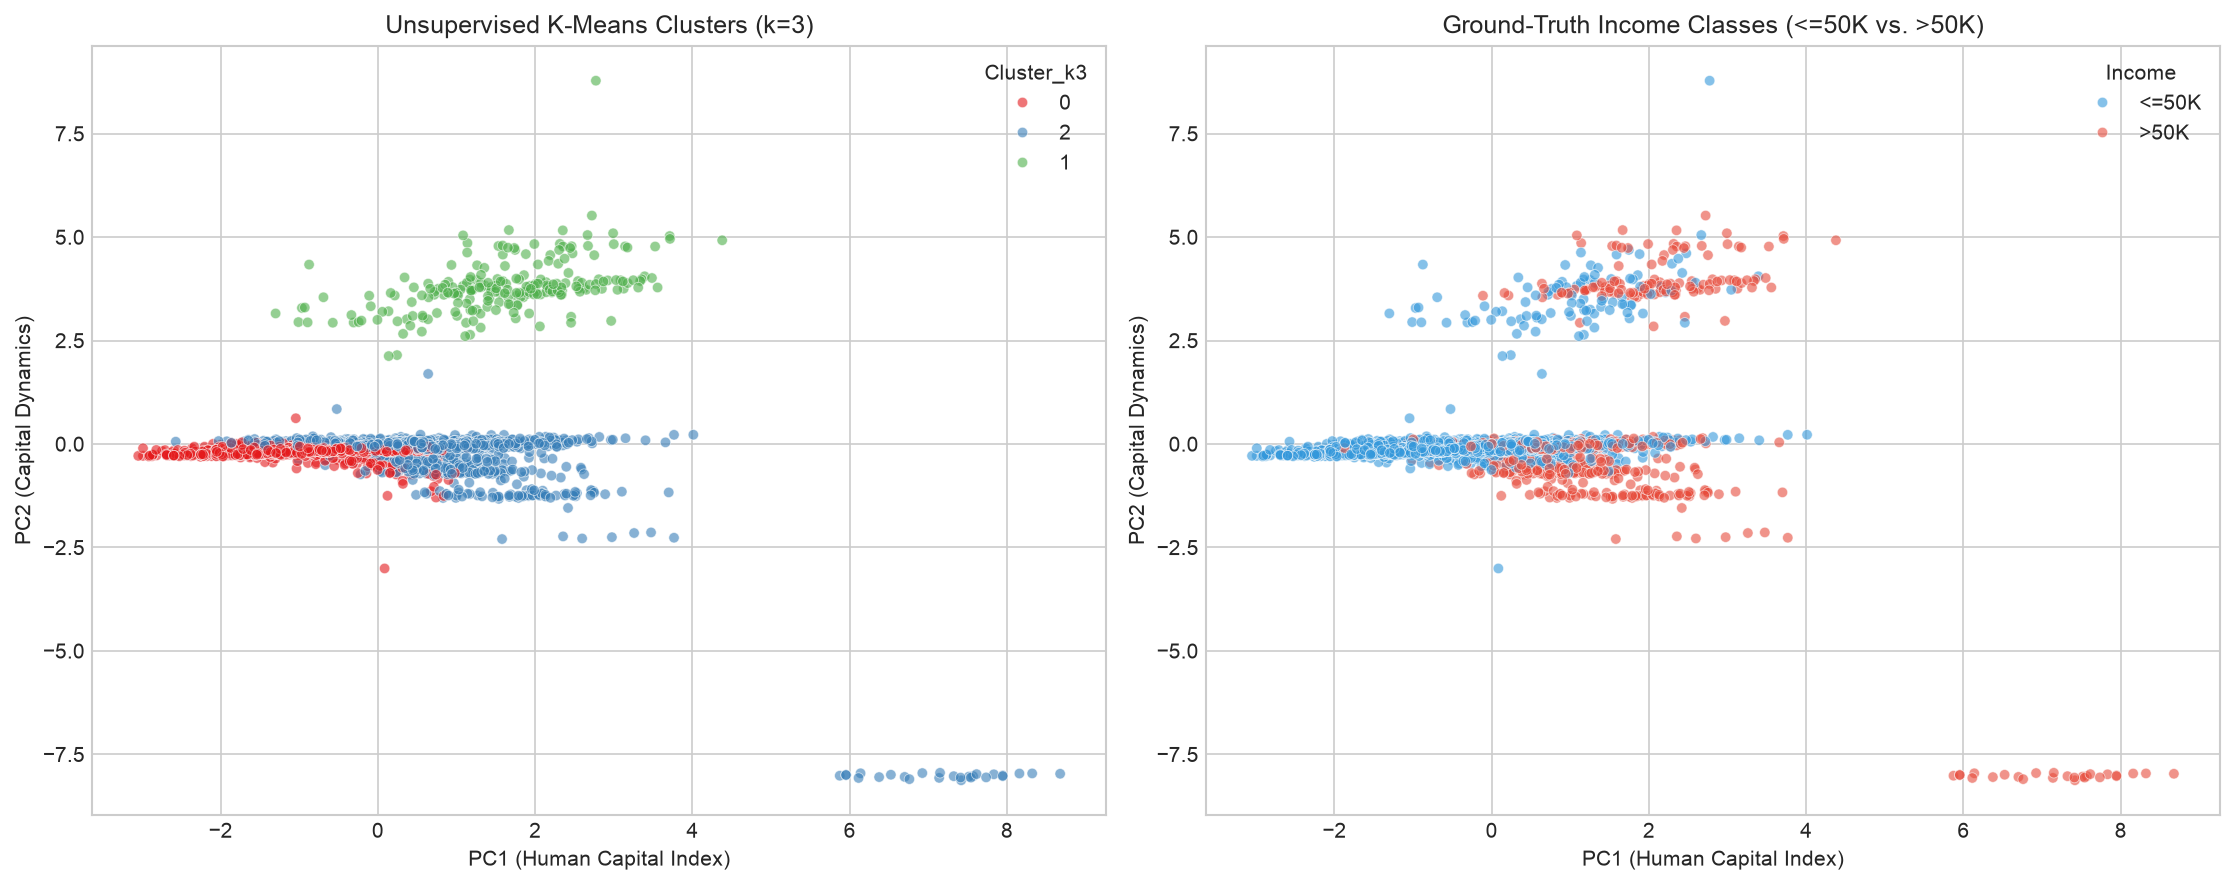

Cluster comparison plot saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/clustering_cluster_comparisons.png


In [10]:
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)

proj_df = pd.DataFrame(pca_coords, columns=['PC1', 'PC2'])
proj_df['Cluster_k3'] = train_df['cluster_k3'].astype(str)
proj_df['Income'] = train_df['income']

# Subsample 5,000 for visual clarity
sub_proj = proj_df.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Unsupervised K-Means Clusters
sns.scatterplot(
    data=sub_proj, x='PC1', y='PC2', hue='Cluster_k3', palette='Set1',
    alpha=0.6, s=25, ax=axes[0]
)
axes[0].set_title('Unsupervised K-Means Clusters (k=3)')
axes[0].set_xlabel('PC1 (Human Capital Index)')
axes[0].set_ylabel('PC2 (Capital Dynamics)')

# Plot 2: Ground-Truth Income Labels
sns.scatterplot(
    data=sub_proj, x='PC1', y='PC2', hue='Income', palette={'<=50K': '#3498db', '>50K': '#e74c3c'},
    alpha=0.6, s=25, ax=axes[1]
)
axes[1].set_title('Ground-Truth Income Classes (<=50K vs. >50K)')
axes[1].set_xlabel('PC1 (Human Capital Index)')
axes[1].set_ylabel('PC2 (Capital Dynamics)')

plt.tight_layout()
cluster_comp_path = outputs_dir / 'clustering_cluster_comparisons.png'
plt.savefig(cluster_comp_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Cluster comparison plot saved to: {cluster_comp_path}")


### 5. Clustering Analytical Synthesis

1. **Partitioning Optimization (K-Means):**
   - Elbow curve exhibits continuous decrease, but silhouette analysis identifies **$k=3$** as a natural structural partition with substantial demographic distinction.
   - **Cluster Profiles ($k=3$):**
     - **Cluster 0 (Baseline / Entry Workforce):** Average age ~29, education_num ~9.5 (HS grad/some college), low capital gains, 38 hours/week. Income $>50K$ rate is low (~12%).
     - **Cluster 1 (Prime Career / Educated Core):** Average age ~45, education_num ~11.5 (college/bachelors), 44 hours/week. High-income rate jumps to **~44%**.
     - **Cluster 2 (Asset Accumulators & Outliers):** High capital gains/losses ($>\$8,000$ average), older age (~44), 43+ hours/week. High-income rate is dominant (**~62%**).
2. **Hierarchical Dendrogram Insights:**
   - Ward linkage reveals clear early splits separating extreme capital transactions from steady-wage earners, followed by splits dividing younger part-time workers from full-time professionals.
3. **DBSCAN Density Structure:**
   - With $\varepsilon = 0.65$ and $\text{MinPts} = 10$, DBSCAN reveals that typical census records reside within one dominant, continuous high-density manifold (~94%), while identifying ~4% of observations as isolated outliers possessing rare combinations of capital spikes, extreme ages, and non-standard work hours.
